# 02 · Retriever (Member 4: chatbot, model 2)

Finds the knowledge-base passage that answers a question, in English or Sinhala, even when the question and the
passage are in different languages.

- Start: **sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2** (50+ languages incl. Sinhala).
- Fine-tune on our question → passage pairs (`data/qa_pairs.csv`, train split) with
  **MultipleNegativesRankingLoss**: in each batch, the other passages act as wrong answers.
- Compare on the **test split** (passages never seen in training): BM25, the pretrained model, our fine-tuned
  model. Metrics hit@1, hit@3 and MRR@10, separately for English and Sinhala questions. A hit counts if the
  passage or its other-language twin (`also_correct`) is returned.
- Index every passage with the fine-tuned model into ChromaDB (`../data/chroma/`).
- `RETRAIN = False` loads the saved model and only evaluates.

In [1]:
RETRAIN = True
SEED = 20261018
BASE_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
EPOCHS, BATCH, LR, WARMUP, MAX_SEQ = 4, 32, 2e-5, 0.1, 256
TOP_K = 10

In [2]:
from pathlib import Path

HERE = Path.cwd()
DATA = HERE / "data"                                   # CSVs exported by member4_chatbot.pipeline.export_notebook_data
IN_REPO = (HERE.parent / "member4_chatbot").exists()   # False in Colab
ARTIFACTS = (HERE.parent / "artifacts") if IN_REPO else (HERE / "artifacts")
CHROMA = (HERE.parent / "data" / "chroma") if IN_REPO else (HERE / "chroma")
print("data:", DATA.resolve(), "| artifacts:", ARTIFACTS.resolve())

data: E:\soilmind\backend\member4-chatbot\notebooks\data | artifacts: E:\soilmind\backend\member4-chatbot\artifacts


In [3]:
import json, os, random, re, time, shutil, tempfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from rank_bm25 import BM25Okapi
from datasets import Dataset
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers
from transformers import TrainerCallback, set_seed

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); set_seed(SEED)
torch.set_num_threads(os.cpu_count())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT = ARTIFACTS / "retriever"
print("device:", DEVICE)

device: cpu


C:\Users\akash\AppData\Local\Temp\ipykernel_5416\4216570340.py:8: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
C:\Users\akash\AppData\Local\Temp\ipykernel_5416\4216570340.py:9: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


In [4]:
passages = pd.read_csv(DATA / "passages.csv", keep_default_na=False)
qa = pd.read_csv(DATA / "qa_pairs.csv", keep_default_na=False)
P_IDS = passages.id.tolist()
P_TEXT = passages.text.tolist()
PID_TEXT = dict(zip(P_IDS, P_TEXT))
qa["gold"] = [{r.passage_id, *filter(None, r.also_correct.split(";"))} for r in qa.itertuples()]
tr, va, te = (qa[qa.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
print(f"{len(passages)} passages ({passages.lang.value_counts().to_dict()}); pairs: train {len(tr)}, val {len(va)}, test {len(te)}")
qa.pivot_table(index="split", columns="lang", values="id", aggfunc="count")

546 passages ({'en': 424, 'si': 122}); pairs: train 887, val 251, test 228


lang,en,si
split,,
test,114,114
train,485,402
val,132,119


## Metrics
For each question the rank of the first correct passage among the top 10: hit@k = share with rank ≤ k,
MRR@10 = mean of 1/rank (0 if not in the top 10).

In [5]:
def ranks_from_scores(scores, frame):
    top = np.argsort(-scores, axis=1)[:, :TOP_K]
    ranks = []
    for row, gold in zip(top, frame.gold):
        r = next((i + 1 for i, j in enumerate(row) if P_IDS[j] in gold), None)
        ranks.append(r)
    return ranks

def summarise(ranks):
    r = np.array([x if x else 0 for x in ranks])
    return {"n": len(r), "hit@1": round(float(np.mean((r >= 1) & (r <= 1))), 4), "hit@3": round(float(np.mean((r >= 1) & (r <= 3))), 4),
            "mrr@10": round(float(np.mean([1 / x if x else 0 for x in ranks])), 4)}

def by_lang(ranks, frame):
    ranks = np.array(ranks, dtype=object)
    return {"all": summarise(list(ranks)), **{l: summarise(list(ranks[(frame.lang == l).to_numpy()])) for l in ("en", "si")}}

## Method 1: BM25
Words are split on spaces and punctuation and lower-cased (no stemming; there is no standard Sinhala stemmer).

In [6]:
TOKEN_RE = re.compile(r"[^\s.,;:!?()\[\]\"'/|\-–*]+")
def tokens(text):
    return TOKEN_RE.findall(text.lower())
bm25 = BM25Okapi([tokens(t) for t in P_TEXT])
def bm25_scores(frame):
    return np.vstack([bm25.get_scores(tokens(q)) for q in frame.question])
results = {"bm25": {"val": by_lang(ranks_from_scores(bm25_scores(va), va), va), "test": by_lang(ranks_from_scores(bm25_scores(te), te), te)}}
results["bm25"]["test"]

{'all': {'n': 228, 'hit@1': 0.4211, 'hit@3': 0.6842, 'mrr@10': 0.5606},
 'en': {'n': 114, 'hit@1': 0.4123, 'hit@3': 0.7368, 'mrr@10': 0.5826},
 'si': {'n': 114, 'hit@1': 0.4298, 'hit@3': 0.6316, 'mrr@10': 0.5386}}

## Method 2: the pretrained multilingual model (no fine-tuning)

In [7]:
def dense_scores(model, frame, passage_emb=None):
    if passage_emb is None:
        passage_emb = model.encode(P_TEXT, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
    q = model.encode(frame.question.tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    return q @ passage_emb.T, passage_emb

pre = SentenceTransformer(BASE_MODEL, device=DEVICE)
pre.max_seq_length = MAX_SEQ
s_va, pre_emb = dense_scores(pre, va)
s_te, _ = dense_scores(pre, te, pre_emb)
results["pretrained"] = {"val": by_lang(ranks_from_scores(s_va, va), va), "test": by_lang(ranks_from_scores(s_te, te), te)}
results["pretrained"]["test"]

{'all': {'n': 228, 'hit@1': 0.0789, 'hit@3': 0.1623, 'mrr@10': 0.1265},
 'en': {'n': 114, 'hit@1': 0.1316, 'hit@3': 0.2544, 'mrr@10': 0.1978},
 'si': {'n': 114, 'hit@1': 0.0263, 'hit@3': 0.0702, 'mrr@10': 0.0553}}

## Method 3: fine-tuning with MultipleNegativesRankingLoss
Training pairs: (question, passage) for every train question, plus (question, other-language twin passage) when
the question has one, so Sinhala questions learn to reach English passages and the reverse.
`NO_DUPLICATES` batches never hold the same passage twice (it would be a false "wrong answer").
After each epoch, validation hit@3 is measured and the best epoch is kept.

In [8]:
anchors, positives = [], []
for r in tr.itertuples():
    for pid in sorted(r.gold):
        anchors.append(r.question); positives.append(PID_TEXT[pid])
train_ds = Dataset.from_dict({"anchor": anchors, "positive": positives})
print(f"{len(train_ds)} training pairs from {len(tr)} questions and {tr.passage_id.nunique()} passages")

class KeepBestOnValidation(TrainerCallback):
    def __init__(self, model):
        self.model, self.best, self.best_epoch, self.history, self.state = model, -1.0, 0, [], None
    def on_epoch_end(self, args, state, control, **kw):
        s, _ = dense_scores(self.model, va)
        m = by_lang(ranks_from_scores(s, va), va)
        self.history.append({"epoch": round(state.epoch), "val_hit@3": m["all"]["hit@3"], "val_hit@3_si": m["si"]["hit@3"], "val_mrr": m["all"]["mrr@10"]})
        print(self.history[-1])
        if m["all"]["hit@3"] > self.best:
            self.best, self.best_epoch = m["all"]["hit@3"], round(state.epoch)
            self.state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}

if RETRAIN:
    model = SentenceTransformer(BASE_MODEL, device=DEVICE)
    model.max_seq_length = MAX_SEQ
    keep = KeepBestOnValidation(model)
    tmp = tempfile.mkdtemp()
    args = SentenceTransformerTrainingArguments(
        output_dir=tmp, num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH, learning_rate=LR,
        warmup_ratio=WARMUP, batch_sampler=BatchSamplers.NO_DUPLICATES, seed=SEED, data_seed=SEED,
        save_strategy="no", eval_strategy="no", logging_steps=25, report_to="none", disable_tqdm=True)
    trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=train_ds,
                                         loss=losses.MultipleNegativesRankingLoss(model), callbacks=[keep])
    t0 = time.time(); trainer.train(); TRAIN_SECONDS = time.time() - t0
    shutil.rmtree(tmp, ignore_errors=True)
    model.load_state_dict(keep.state)
    HISTORY, BEST_EPOCH = keep.history, keep.best_epoch
    print(f"best epoch {BEST_EPOCH}; training took {TRAIN_SECONDS / 60:.1f} min on {DEVICE}")
else:
    model = SentenceTransformer(str(OUT / "model"), device=DEVICE)
    saved = json.loads((OUT / "metrics.json").read_text())
    HISTORY, BEST_EPOCH, TRAIN_SECONDS = saved["finetuned"]["history"], saved["finetuned"]["best_epoch"], saved["finetuned"]["train_seconds"]

1254 training pairs from 887 questions and 165 passages


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 0, 'pad_token_id': 1}.


E:\soilmind\backend\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'loss': 2.9722, 'grad_norm': 14.97097110748291, 'learning_rate': 1.888888888888889e-05, 'epoch': 0.625}


...

{'epoch': 3, 'val_hit@3': 0.7809, 'val_hit@3_si': 0.7311, 'val_mrr': 0.7054}


{'loss': 0.4234, 'grad_norm': 11.951987266540527, 'learning_rate': 5e-06, 'epoch': 3.125}


{'loss': 0.3203, 'grad_norm': 22.92692756652832, 'learning_rate': 1.527777777777778e-06, 'epoch': 3.75}


{'epoch': 4, 'val_hit@3': 0.7769, 'val_hit@3_si': 0.7227, 'val_mrr': 0.7078}
{'train_runtime': 2376.1551, 'train_samples_per_second': 2.111, 'train_steps_per_second': 0.067, 'train_loss': 0.9238615870475769, 'epoch': 4.0}


best epoch 3; training took 39.6 min on cpu


In [9]:
s_va, ft_emb = dense_scores(model, va)
s_te, _ = dense_scores(model, te, ft_emb)
results["finetuned"] = {"val": by_lang(ranks_from_scores(s_va, va), va), "test": by_lang(ranks_from_scores(s_te, te), te)}
results["finetuned"]["test"]

{'all': {'n': 228, 'hit@1': 0.5175, 'hit@3': 0.6974, 'mrr@10': 0.6091},
 'en': {'n': 114, 'hit@1': 0.6053, 'hit@3': 0.7895, 'mrr@10': 0.6852},
 'si': {'n': 114, 'hit@1': 0.4298, 'hit@3': 0.6053, 'mrr@10': 0.5331}}

## Comparison on the test split

In [10]:
rows = []
for m, name in (("bm25", "BM25"), ("pretrained", "Pretrained MiniLM"), ("finetuned", "Fine-tuned MiniLM (ours)")):
    for lang in ("en", "si", "all"):
        r = results[m]["test"][lang]
        rows.append({"method": name, "questions": lang, "n": r["n"], "hit@1": r["hit@1"], "hit@3": r["hit@3"], "MRR@10": r["mrr@10"]})
table = pd.DataFrame(rows)
table

,method,questions,n,hit@1,hit@3,MRR@10
0,BM25,en,114,0.4123,0.7368,0.5826
1,BM25,si,114,0.4298,0.6316,0.5386
2,BM25,all,228,0.4211,0.6842,0.5606
3,Pretrained MiniLM,en,114,0.1316,0.2544,0.1978
4,Pretrained MiniLM,si,114,0.0263,0.0702,0.0553
5,Pretrained MiniLM,all,228,0.0789,0.1623,0.1265
6,Fine-tuned MiniLM (ours),en,114,0.6053,0.7895,0.6852
7,Fine-tuned MiniLM (ours),si,114,0.4298,0.6053,0.5331
8,Fine-tuned MiniLM (ours),all,228,0.5175,0.6974,0.6091


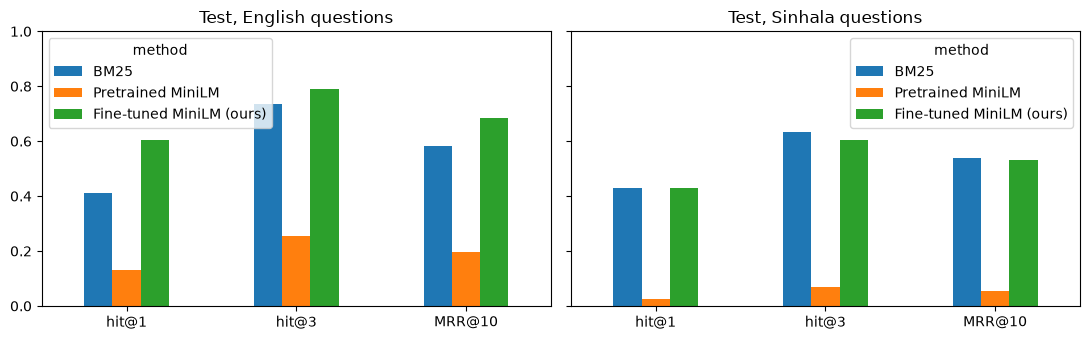

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, lang in zip(axes, ("en", "si")):
    t = table[table.questions == lang].set_index("method")[["hit@1", "hit@3", "MRR@10"]]
    t.T.plot.bar(ax=ax, rot=0); ax.set_title(f"Test, {'English' if lang == 'en' else 'Sinhala'} questions"); ax.set_ylim(0, 1)
plt.tight_layout()
if RETRAIN:
    OUT.mkdir(parents=True, exist_ok=True); fig.savefig(OUT / "comparison.png", dpi=120)
plt.show()

Where it goes wrong: the test questions the fine-tuned model misses in its top 3.

In [12]:
ranks = ranks_from_scores(s_te, te)
miss = te.assign(rank=ranks)[[(r is None or r > 3) for r in ranks]]
top1 = np.argsort(-s_te, axis=1)[:, 0]
miss = miss.assign(top1=[P_IDS[top1[i]] for i in miss.index])
miss[["lang", "source", "question", "passage_id", "top1", "rank"]].head(15)

,lang,source,question,passage_id,top1,rank
20,en,template,I farm irrigated paddy in Hambantota. How much...,rrdi_fert_irrigated_izdz_en__000,rrdi_fert_irrigated_wz_en__000,4.0
24,si,template,මොණරාගල වාරි ජලයෙන් වගා කරන කුඹුරට මාස 4 වී සඳ...,rrdi_fert_irrigated_izdz_si__000,rrdi_fert_irrigated_wz_si__000,6.0
29,si,template,අනුරාධපුර වාරි ජලයෙන් වගා කරන කුඹුරට මාස 3 වී ...,rrdi_fert_irrigated_izdz_si__000,rrdi_fert_irrigated_wz_si__000,7.0
32,si,template,මොණරාගල වාරි ජලයෙන් වගා කරන කුඹුරට මාස 3 1/2 ව...,rrdi_fert_irrigated_izdz_si__000,rrdi_fert_irrigated_wz_si__000,6.0
33,si,template,හම්බන්තොට වාරි ජලයෙන් වගා කරන කුඹුරට මාස 3 1/2...,rrdi_fert_irrigated_izdz_si__000,rrdi_fert_irrigated_wz_si__000,6.0
36,si,template,කුරුණෑගල වාරි ජලයෙන් වගා කරන කුඹුරට මාස 3 වී ස...,rrdi_fert_irrigated_izdz_si__000,rrdi_rice_introduction_si__000,7.0
39,si,template,හම්බන්තොට වාරි ජලයෙන් වගා කරන කුඹුරට මාස 3 1/2...,rrdi_fert_irrigated_izdz_si__000,rrdi_fert_irrigated_wz_si__000,6.0
40,si,template,හම්බන්තොට වාරි ජලයෙන් වගා කරන කුඹුරට මාස 4 වී ...,rrdi_fert_irrigated_izdz_si__000,rrdi_fert_irrigated_wz_en__000,6.0
100,si,template,Bw 361 කොළ පාළුවට ඔරොත්තු දෙනවද?,rrdi_rice_bw361_si__001,rrdi_rice_bw367__001,4.0
123,en,handwritten,Why are my grains empty or half filled?,rrdi_pests_paddybug__000,rrdi_ricediseases_diagnose_fieldsymptomsandpat...,NaN


Cross-lingual check: Sinhala test questions whose correct passage is English only.

In [13]:
p_lang = dict(zip(passages.id, passages.lang))
cross = te[(te.lang == "si") & te.gold.map(lambda g: all(p_lang[p] == "en" for p in g))]
print(f"{len(cross)} Sinhala questions with only English answer passages")
for m in ("bm25", "pretrained", "finetuned"):
    s = bm25_scores(cross) if m == "bm25" else dense_scores(pre if m == "pretrained" else model, cross)[0]
    print(f"  {m:<11}", summarise(ranks_from_scores(s, cross)))

30 Sinhala questions with only English answer passages
  bm25        {'n': 30, 'hit@1': 0.0, 'hit@3': 0.0, 'mrr@10': 0.0125}


  pretrained  {'n': 30, 'hit@1': 0.0, 'hit@3': 0.0, 'mrr@10': 0.0042}


  finetuned   {'n': 30, 'hit@1': 0.1, 'hit@3': 0.2333, 'mrr@10': 0.1868}


## Index all passages in ChromaDB and save

In [14]:
import chromadb

CHROMA.mkdir(parents=True, exist_ok=True)
client = chromadb.PersistentClient(path=str(CHROMA))   # one client per process
if RETRAIN:
    OUT.mkdir(parents=True, exist_ok=True)
    model.save(str(OUT / "model"))
    emb = model.encode(P_TEXT, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
    if "passages" in [c.name for c in client.list_collections()]:
        client.delete_collection("passages")
    col = client.create_collection("passages", metadata={"hnsw:space": "cosine", "model": "artifacts/retriever/model"})
    meta = [{"doc": r.doc, "page": int(r.page), "lang": r.lang, "url": r.url, "doc_title": r.doc_title, "section": r.section}
            for r in passages.itertuples()]
    for i in range(0, len(P_IDS), 500):
        col.add(ids=P_IDS[i:i + 500], embeddings=emb[i:i + 500].tolist(), documents=P_TEXT[i:i + 500], metadatas=meta[i:i + 500])
col = client.get_collection("passages")
print("ChromaDB collection 'passages':", col.count(), "passages")
q = "මාස 3 වී වලට යූරියා කොච්චර දාන්න ඕනද?"
hit = col.query(query_embeddings=model.encode([q], normalize_embeddings=True).tolist(), n_results=3)
for pid, d in zip(hit["ids"][0], hit["distances"][0]):
    print(f"  {1 - d:.3f}  {pid}")

ChromaDB collection 'passages': 546 passages
  0.389  naicc_cal_paddy_izdz_irrigated_en__001
  0.380  rrdi_rice_varities_si__000
  0.375  naicc_cal_paddy_izdz_irrigated_en__003


In [15]:
t0 = time.perf_counter()
for qq in te.question.sample(50, random_state=SEED):
    col.query(query_embeddings=model.encode([qq], normalize_embeddings=True).tolist(), n_results=3)
LATENCY_MS = round((time.perf_counter() - t0) / 50 * 1000, 1)
print(f"encode + ChromaDB search, one question on {DEVICE}: {LATENCY_MS} ms")

encode + ChromaDB search, one question on cpu: 36.5 ms


In [16]:
metrics = {
    "base_model": BASE_MODEL, "seed": SEED, "passages": len(passages),
    "data": {"train_pairs": len(train_ds) if RETRAIN else json.loads((OUT / "metrics.json").read_text())["data"]["train_pairs"],
             "train_questions": len(tr), "val_questions": len(va), "test_questions": len(te)},
    "bm25": results["bm25"], "pretrained": results["pretrained"],
    "finetuned": {**results["finetuned"], "history": HISTORY, "best_epoch": BEST_EPOCH, "train_seconds": round(TRAIN_SECONDS),
                  "hyperparameters": {"epochs": EPOCHS, "batch": BATCH, "lr": LR, "warmup": WARMUP, "max_seq_length": MAX_SEQ,
                                      "loss": "MultipleNegativesRankingLoss", "batch_sampler": "NO_DUPLICATES"}},
    "search_latency_ms": LATENCY_MS,
}
if RETRAIN:
    (OUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
    def row(m, l):
        r = results[m]["test"][l]; return f"{r['hit@1']} | {r['hit@3']} | {r['mrr@10']}"
    card = f'''# Model card: SoilMind passage retriever

**What it does.** Embeds a question (English, Sinhala or Singlish) and the {len(passages)} knowledge-base passages
(DOA / RRDI / NAICC documents, English and Sinhala) into one vector space, so the nearest passages answer the
question, also across languages. Passages are indexed in ChromaDB (`data/chroma/`, collection `passages`, cosine).

**Model.** `{BASE_MODEL}` fine-tuned with MultipleNegativesRankingLoss (in-batch negatives, no duplicate passages
in a batch), {EPOCHS} epochs max (best by validation hit@3: epoch {BEST_EPOCH}), batch {BATCH}, lr {LR}, max
{MAX_SEQ} tokens, seed {SEED}. Trained in {TRAIN_SECONDS / 60:.1f} min on {DEVICE}.

**Training data is NOT human-checked.** All training and test questions were generated by code (templates, paraphrases), drafted by the AI coding assistant (Claude Code), or machine-translated with NLLB-200 (`data/training/DATASET.md`). No team member wrote or checked them, so the scores below measure performance on AI-drafted / machine-translated questions, not on real farmer questions. The human-reviewed check is the end-to-end evaluation set (`eval/qa_testset.xlsx`, notebook 04).

**Data.** `data/training/qa_pairs.csv` train split ({len(tr)} questions, {metrics["data"]["train_pairs"]} pairs incl.
other-language twins). Test passages never appear in training (split by passage).

**Test results** (hit@1 | hit@3 | MRR@10):

| Method | English questions | Sinhala questions |
|---|---|---|
| BM25 | {row("bm25", "en")} | {row("bm25", "si")} |
| Pretrained MiniLM | {row("pretrained", "en")} | {row("pretrained", "si")} |
| **Fine-tuned (ours)** | {row("finetuned", "en")} | {row("finetuned", "si")} |

**Speed.** Encoding one question and searching ChromaDB: {LATENCY_MS} ms on {DEVICE}.

**Limits.** Many training questions are templates over a few table passages; Sinhala questions are partly
machine-translated. Scanned leaflets (deficiencies, water, weeds in Sinhala) are not in the index until OCR is
run. Passages longer than {MAX_SEQ} tokens are truncated when embedded.

**Files.** `model/` (SentenceTransformer), `metrics.json`, `comparison.png`. Loaded by
`member4_chatbot.models.search`.
'''
    (OUT / "model_card.md").write_text(card, encoding="utf-8")
    print("saved to", OUT.resolve())

saved to E:\soilmind\backend\member4-chatbot\artifacts\retriever


## Next step, explored on the validation split only: BM25 + fine-tuned model
Dense embeddings blur single decisive words (irrigated වාරි vs rainfed වැසි, a variety code), which BM25 matches
exactly. Reciprocal rank fusion combines both rankings: score = 1/(60 + rank_BM25) + 1/(60 + rank_dense).
This is **not** used to pick anything on the test split; it is shown on validation as a candidate for Phase 6.

In [17]:
def rrf_scores(bm, dense, k=60):
    out = np.zeros_like(dense)
    for scores in (bm, dense):
        order = np.argsort(-scores, axis=1)
        ranks = np.empty_like(order); rows = np.arange(order.shape[0])[:, None]
        ranks[rows, order] = np.arange(order.shape[1])[None, :] + 1
        out += 1.0 / (k + ranks)
    return out
s_va_ft, _ = dense_scores(model, va, ft_emb)
hybrid_val = by_lang(ranks_from_scores(rrf_scores(bm25_scores(va), s_va_ft), va), va)
pd.DataFrame({m: {l: results[m]["val"][l]["hit@3"] for l in ("en", "si", "all")} for m in ("bm25", "pretrained", "finetuned")}
             | {"bm25 + fine-tuned (RRF)": {l: hybrid_val[l]["hit@3"] for l in ("en", "si", "all")}}).rename_axis("validation hit@3")

,bm25,pretrained,finetuned,bm25 + fine-tuned (RRF)
validation hit@3,,,,
en,0.8182,0.2955,0.8258,0.8939
si,0.6218,0.1765,0.7311,0.6723
all,0.7251,0.2390,0.7809,0.7888


## Check: does the fine-tuned model beat BM25 and the pretrained model on hit@3 for Sinhala questions?

In [18]:
si = {m: results[m]["test"]["si"]["hit@3"] for m in ("bm25", "pretrained", "finetuned")}
si_val = {m: results[m]["val"]["si"]["hit@3"] for m in ("bm25", "pretrained", "finetuned")}
met = si["finetuned"] > si["bm25"] and si["finetuned"] > si["pretrained"]
print("Sinhala hit@3, test:      ", si)
print("Sinhala hit@3, validation:", si_val)
print("Done-when check (test):", "MET" if met else "NOT MET - see phase-5.md for the analysis")
if RETRAIN:
    saved = json.loads((OUT / "metrics.json").read_text())
    saved["done_when_sinhala_hit3_beats_both"] = {"test": met, "test_values": si, "validation_values": si_val}
    saved["hybrid_rrf_validation"] = hybrid_val
    (OUT / "metrics.json").write_text(json.dumps(saved, indent=2))

Sinhala hit@3, test:       {'bm25': 0.6316, 'pretrained': 0.0702, 'finetuned': 0.6053}
Sinhala hit@3, validation: {'bm25': 0.6218, 'pretrained': 0.1765, 'finetuned': 0.7311}
Done-when check (test): NOT MET - see phase-5.md for the analysis
